# 07. Sampling correlation

**What you will achieve:** Explore the relationship between the spatial and amplitude random multipliers, including independent and coupled variables. Domain correlations are distinct from variable coupling.

**For your own data:** replace `INPUT_FILE` first; then change the brief settings cell as needed. This notebook uses `tests/fixtures/input_2.leapr` and the real TARA Core interfaces. There is no backend execution here.


## Scientific idea: there are two different kinds of dependence

`correlation_strategy` determines how perturbations depend on **different energy domains**. `variable_coupling` determines whether **amplitude and spatial** parameters share the stochastic state within those domains. They are separate configuration choices.

This example selects `random_group` and `coupled`. Coupling does not imply equal physical changes: one dimension is measured as a percentage of PDOS amplitude and the other in meV of energy displacement. Inspect per-domain provenance rather than computing a direct difference between quantities with incompatible units.


## 1. Locate TARA

The next cell finds TARA and imports the sampling APIs.

In [1]:
# Locate the TARA repository so this notebook works from any of its subdirectories.
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if
     (p / 'core' / 'config.py').is_file() and
     (p / 'core' / 'sampler' / 'concrete_samplers.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter inside your TARA repository.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from core.config import TaraConfig
from core.data.input_pdos import PhononSpectra
from core.sampler.concrete_samplers import TaraSampler
from input_output.factory import load_file_object

print(f'TARA root: {PROJECT_ROOT}')


TARA root: /home/aitor/postdoc/tara_preview_V3_5


## 2. Select the required inputs

**Required settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `INPUT_FILE` | `tests/fixtures/input_2.leapr` | Source of the reference phonon spectrum. |

In [2]:
INPUT_FILE = PROJECT_ROOT / 'tests' / 'fixtures' / 'input_2.leapr'
if not INPUT_FILE.is_file():
    raise FileNotFoundError(f'Example LEAPR fixture is missing: {INPUT_FILE}')

## 3. Load the graphite reference

Load the selected input and prepare the normalized reference PDOS.

In [3]:
file_template, raw_pdos = load_file_object(filepath=INPUT_FILE)
reference_spectrum = PhononSpectra(pdos=raw_pdos, auto_normalize=True)
print(f'Input: {INPUT_FILE.name}; normalized area: {reference_spectrum.integral:.6f}')

Input: input_2.leapr; normalized area: 1.000000


## 4. Set up this experiment

Change the grouping and coupling strategies to examine dependence between perturbations.

**Required settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `MAX_ENERGY_SHIFT_MEV` | `1.0` | Maximum phonon-energy displacement in meV. |
| `MAX_AMPLITUDE_SHIFT_PCT` | `5.0` | Maximum relative amplitude change in percent. |
| `N_SAMPLES` | `300` | Number of stochastic samples used to estimate correlations. |

In [4]:
MAX_ENERGY_SHIFT_MEV = 1.0
MAX_AMPLITUDE_SHIFT_PCT = 5.0
N_SAMPLES = 300

**Optional settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `RANDOM_SEED` | `0` | Reproducible seed passed to TaraConfig for Latin hypercube sampling. |
| `BATCH_SIZE` | `512` | Number of samples processed per internal chunk. |
| `AMPLITUDE_METHOD` | `'fast'` | Amplitude perturbation method. |
| `SPATIAL_METHOD` | `'diffeomorphic'` | Energy-grid perturbation method. |
| `CORRELATION_STRATEGY` | `'independent'` | Choose independent domain shifts or a shared shift within a group. |
| `VARIABLE_COUPLING` | `'independent'` | Choose separate or shared amplitude and energy-shift coordinates. |

In [5]:
RANDOM_SEED = 0
BATCH_SIZE = 512
AMPLITUDE_METHOD = 'fast'
SPATIAL_METHOD = 'diffeomorphic'
CORRELATION_STRATEGY = 'independent'
VARIABLE_COUPLING = 'independent'

In [6]:
# Validate all perturbation bounds and sampling strategies using TaraConfig.
configuration = TaraConfig(
    max_energy_shift_mev=MAX_ENERGY_SHIFT_MEV,
    max_amplitude_shift_pct=MAX_AMPLITUDE_SHIFT_PCT,
    n_samples=N_SAMPLES,
    random_seed=RANDOM_SEED,
)

# Initialize TaraSampler with the selected amplitude and spatial methods.
sampler = TaraSampler(
    config=configuration,
    spectra=reference_spectrum,
    amplitude_method=AMPLITUDE_METHOD,
    spatial_method=SPATIAL_METHOD,
)

## 5. Generate the ensemble

The actual sampling uses a reproducible seed. `batch_size` controls numerical chunking and is not a limit on sample count. The baseline remains in `ensemble.reference`, and every `ensemble[i]` is a stochastic realization.

In [7]:
from notebooks.tara_plotting import plot_PDOS
import matplotlib.pyplot as plt

In [8]:
# Generate the stochastic spectra and preserve the original baseline separately.
ensemble = sampler.generate_ensemble(
    batch_size=BATCH_SIZE
)

assert len(ensemble) == N_SAMPLES
assert ensemble.reference is not None
print(f'Stochastic realizations: {len(ensemble)}')
print('The reference is stored at ensemble.reference, never at ensemble[0].')

Stochastic realizations: 300
The reference is stored at ensemble.reference, never at ensemble[0].


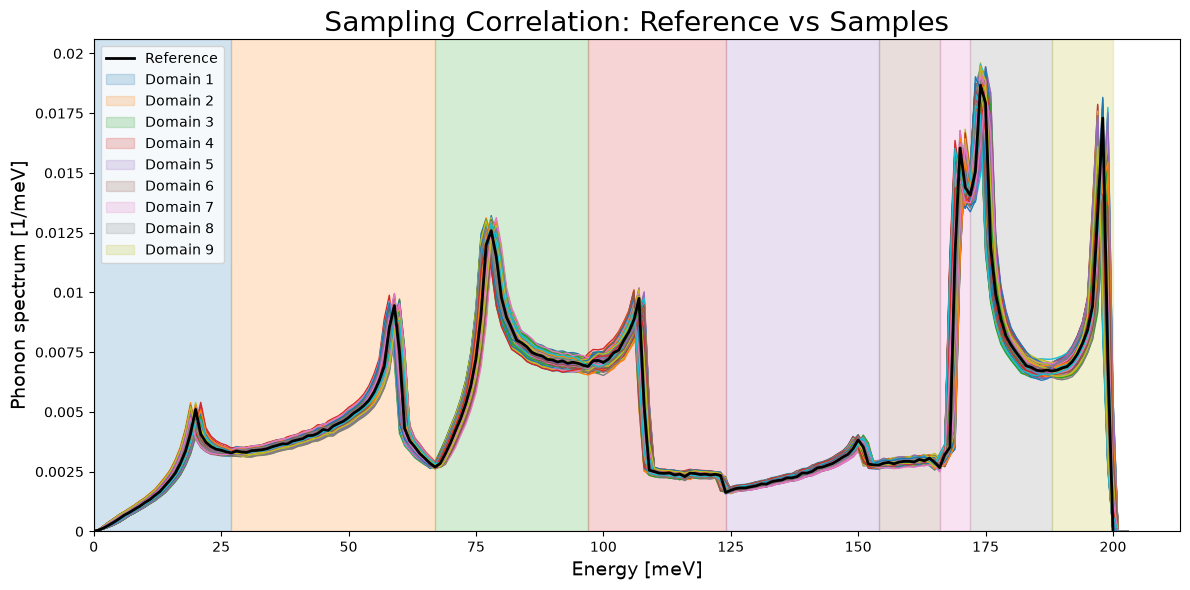

In [9]:
# Plot the reference PDOS and all generated spectra.
fig, ax = plt.subplots(figsize=(12, 6))

plot_PDOS(
    ax,
    list(ensemble),
    ensemble.reference,
    title="Sampling Correlation: Reference vs Samples",
)

# Highlight the actual perturbation domains recorded by the sampler.
boundaries = ensemble.sampling_blocks[0].boundaries
colors = plt.cm.tab10.colors

for i, (start, end) in enumerate(boundaries):
    ax.axvspan(
        start,
        end,
        color=colors[i % len(colors)],
        alpha=0.20,
        label=f"Domain {i + 1}",
    )

ax.legend(loc="best")
plt.tight_layout()
plt.show()

## 6. Visualize the Perturbation Correlation Matrices

The previous PDOS plot shows the spectral effects of stochastic perturbations. We now examine the correlations responsible for these changes.

Three Pearson correlation matrices are computed from the perturbations recorded in the generated ensemble:

- **Energy-shift correlation:** dependence between the energy displacements assigned to different domains.
- **Amplitude-shift correlation:** dependence between amplitude variations across domains.
- **Energy–amplitude correlation:** coupling between energy displacement and amplitude variation, including interactions across domains.

Correlation coefficients range from **−1** (perfect anticorrelation) to **+1** (perfect correlation), with values near zero indicating little linear association.

The matrices describe the realized stochastic perturbations, not correlations calculated directly from PDOS intensities. For reliable estimates of independent or partially correlated variables, a larger ensemble than the initial three samples is recommended.

In [10]:
# Recover the actual physical perturbations for every sample.
generations = [
    ensemble.sample_generation(i)
    for i in range(len(ensemble))
]

energy_shifts = np.asarray(
    [g.energy_shift_mev for g in generations],
    dtype=float,
)

amplitude_shifts = np.asarray(
    [g.amplitude_shift_pct for g in generations],
    dtype=float,
)

n_samples, n_domains = energy_shifts.shape

if n_samples < 2:
    raise ValueError(
        "At least two samples are required to calculate correlations."
    )

if amplitude_shifts.shape != energy_shifts.shape:
    raise ValueError(
        "Energy and amplitude perturbations have incompatible shapes."
    )

In [11]:
# Calculate the correlation matrixs

def pearson_matrix(x, y):
    """Calculate pairwise Pearson correlations between matrix columns."""
    x_centered = x - x.mean(axis=0)
    y_centered = y - y.mean(axis=0)

    numerator = x_centered.T @ y_centered
    denominator = np.sqrt(
        np.sum(x_centered**2, axis=0)[:, None]
        * np.sum(y_centered**2, axis=0)[None, :]
    )

    return np.divide(
        numerator,
        denominator,
        out=np.full(numerator.shape, np.nan),
        where=denominator > 0,
    )


# Correlation between energy shifts in different domains.
energy_corr = pearson_matrix(
    energy_shifts,
    energy_shifts,
)

# Correlation between amplitude shifts in different domains.
amplitude_corr = pearson_matrix(
    amplitude_shifts,
    amplitude_shifts,
)

# Cross-correlation between energy and amplitude perturbations.
coupling_corr = pearson_matrix(
    energy_shifts,
    amplitude_shifts,
)

matrices = (
    (energy_corr, "Energy-shift correlation"),
    (amplitude_corr, "Amplitude-shift correlation"),
    (coupling_corr, "Energy–amplitude correlation"),
)

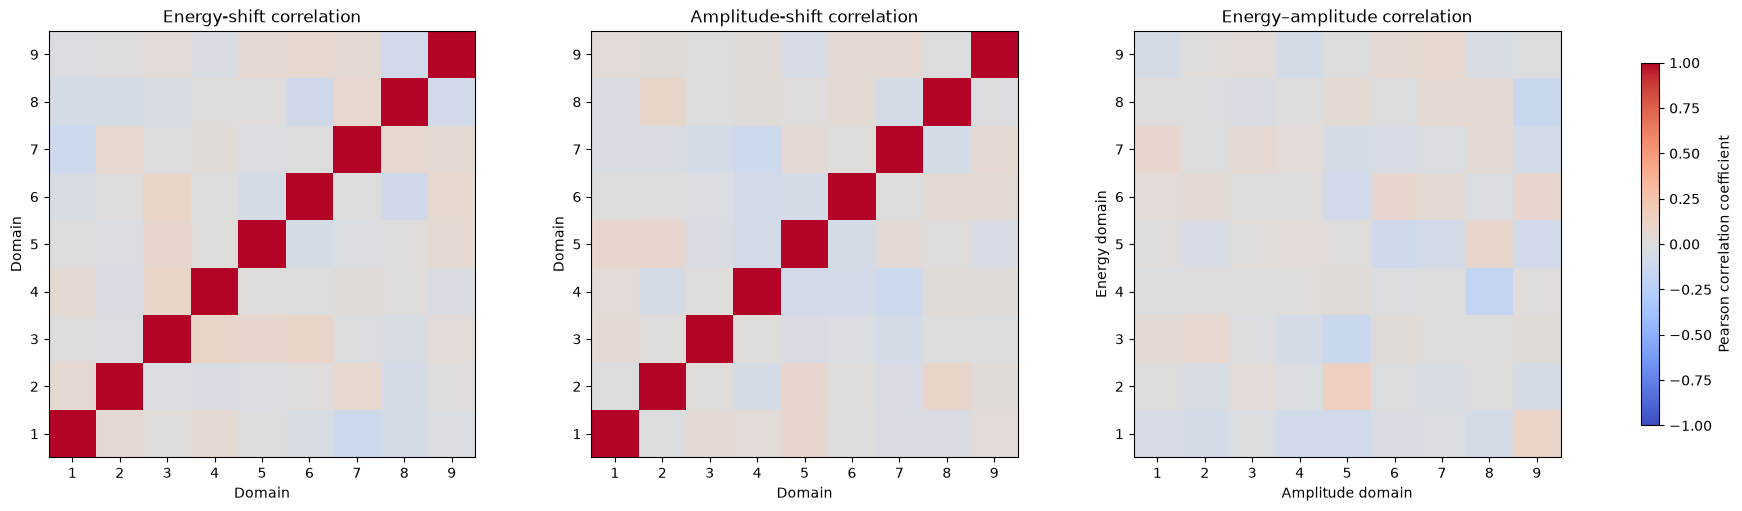

Samples: 300
Perturbation domains: 9
Correlation strategy: independent
Variable coupling: independent


In [12]:
# ---------------------------------------------------------
# Step 6: Plot Perturbation Correlation Matrices
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    constrained_layout=True,
)

cmap = plt.get_cmap("coolwarm").copy()
cmap.set_bad("lightgray")

for ax, (matrix, title) in zip(axes, matrices):
    image = ax.imshow(
        np.ma.masked_invalid(matrix),
        cmap=cmap,
        vmin=-1,
        vmax=1,
        origin="lower",
        interpolation="nearest",
    )

    ax.set_title(title)
    ax.set_xlabel("Amplitude domain" if "Energy–amplitude" in title
                  else "Domain")
    ax.set_ylabel("Energy domain" if "Energy–amplitude" in title
                  else "Domain")

    tick_step = max(1, int(np.ceil(n_domains / 12)))
    ticks = np.arange(0, n_domains, tick_step)

    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(ticks + 1)
    ax.set_yticklabels(ticks + 1)

fig.colorbar(
    image,
    ax=axes,
    shrink=0.85,
    label="Pearson correlation coefficient",
)

plt.show()

print(f"Samples: {n_samples}")
print(f"Perturbation domains: {n_domains}")
print(f"Correlation strategy: {configuration.correlation_strategy}")
print(f"Variable coupling: {configuration.variable_coupling}")